# 02 · Le filtre passe-haut

**But :** construire un filtre qui **garde les aigus** et **atténue les graves**, puis s'en servir pour monter le volume des aigus.

1. L'idée
2. Préparation
3. Le signal de test
4. Passe-haut n° 1 : signal − lissage exponentiel
5. Passe-haut n° 2 : signal − moyenne mobile
6. Comparer avant / après
7. Monter le volume des aigus
8. À retenir

Les notions de base (signal, fréquence, spectre, dB, coupure) sont expliquées au début du notebook 01.

## 1. L'idée

Le passe-haut fait **l'inverse** du passe-bas. Image : le petit haut-parleur d'un téléphone, qui ne reproduit pas les basses.

On n'a pas besoin d'un nouveau calcul :

$$\text{passe-haut}(x) = x - \text{passe-bas}(x)$$

Le passe-bas garde ce qui varie **lentement**. Si on le retire du signal, il reste ce qui varie **vite** : les aigus.

Coupure visée : $f_c$ = 4 000 Hz, la frontière médiums / aigus d'EGALIZE.

## 2. Préparation

**Cellule suivante :** charge les outils, fixe les réglages et recopie les deux passe-bas du notebook 01.

In [1]:
%matplotlib inline
import numpy as np
from outils import *          # mesures, graphiques et écoute (voir outils.py, inutile de le lire)

FC = 4000.0     # fréquence de coupure visée (Hz)
DUREE = 2.0     # durée du signal de test (s)

def lissage_exponentiel(x, alpha):
    # Passe-bas du notebook 01 : y[n] = y[n−1] + alpha × (x[n] − y[n−1])
    y = np.zeros(len(x))
    precedent = 0.0
    for n in range(len(x)):
        precedent = precedent + alpha * (x[n] - precedent)
        y[n] = precedent
    return y


def moyenne_mobile(x, M):
    # Passe-bas du notebook 01 : moyenne des M derniers échantillons
    y = np.zeros(len(x))
    somme = 0.0
    for n in range(len(x)):
        somme = somme + x[n]
        if n >= M:
            somme = somme - x[n - M]
        y[n] = somme / M
    return y

## 3. Le signal de test

Les trois mêmes notes que dans le notebook 01. Le passe-haut doit garder l'aiguë (5 kHz).

**Cellule suivante :** crée le signal de test, l'affiche et propose de l'écouter.

88200 échantillons


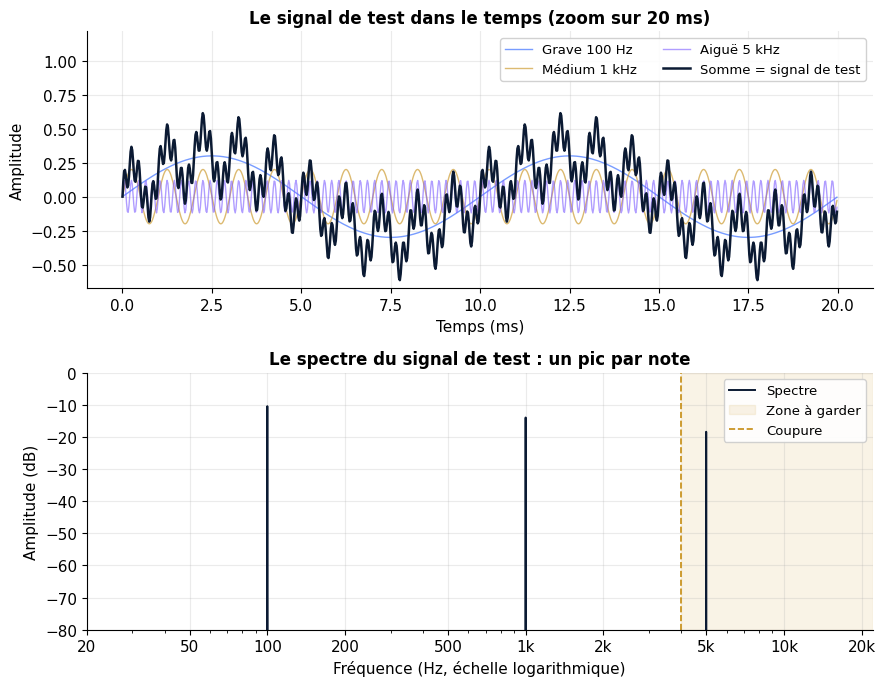

Signal de test — crête : 0.61


In [2]:
t = np.arange(int(DUREE * FS)) / FS        # les instants de mesure : 0, 1/FS, 2/FS, …

NOTES = {                                  # nom : (fréquence en Hz, amplitude)
    "Grave 100 Hz": (100, 0.30),
    "Médium 1 kHz": (1000, 0.20),
    "Aiguë 5 kHz": (5000, 0.12),
}
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in NOTES.items()}   # A·sin(2πft)
x = sum(sinusoides.values())               # le signal de test = la somme des trois notes

print(len(x), "échantillons")

tracer_signal(t, sinusoides, x, coupures=[FC], zone=(FC, FS / 2))
ecouter(x, "Signal de test")

## 4. Passe-haut n° 1 : signal − lissage exponentiel

$$y[n] = x[n] - \text{lissage}(x)[n]$$

**Réglage de α.** La formule $\alpha = 1 - e^{-2\pi f_c/f_s}$ du notebook 01 sert à régler un passe-bas. Une fois le passe-bas soustrait, la coupure se **décale** : on n'obtient pas −3 dB à 4 kHz. On cherche donc le bon α en **essayant** des valeurs : 0,01, 0,02, … 0,99.

**Cellule suivante :** programme le passe-haut, montre le décalage avec la formule, puis essaie les valeurs de α et garde celle qui donne −3 dB à 4 kHz.

In [3]:
def passe_haut_lissage(x, alpha):
    return x - lissage_exponentiel(x, alpha)        # signal − passe-bas


# Avec la formule du notebook 01
alpha_formule = 1 - np.exp(-2 * np.pi * FC / FS)
gain = gain_a(lambda s: passe_haut_lissage(s, alpha_formule), FC)
print(f"Avec la formule : {en_db(gain):.1f} dB à {FC:.0f} Hz (on voulait −3 dB)")

# On essaie 99 valeurs de alpha et on garde la plus proche de −3 dB
essais = np.arange(0.01, 1.0, 0.01)
ecarts = [abs(en_db(gain_a(lambda s: passe_haut_lissage(s, a), FC)) + 3) for a in essais]
alpha = essais[np.argmin(ecarts)]
gain = gain_a(lambda s: passe_haut_lissage(s, alpha), FC)
print(f"alpha retenu = {alpha:.2f} : {en_db(gain):.1f} dB à {FC:.0f} Hz")

y_exp = passe_haut_lissage(x, alpha)

Avec la formule : -5.6 dB à 4000 Hz (on voulait −3 dB)


alpha retenu = 0.30 : -3.0 dB à 4000 Hz


## 5. Passe-haut n° 2 : signal − moyenne mobile

Une précaution : la moyenne des M derniers échantillons représente le signal **tel qu'il était au milieu de la fenêtre**, donc $D = (M-1)/2$ échantillons plus tôt. On décale le signal d'autant avant de soustraire, pour comparer des choses comparables :

$$y[n] = x[n - D] - \text{moyenne}_M(x)[n]$$

On prend M **impair**, pour que D soit un nombre entier. On cherche M en essayant les valeurs 3, 5, 7, …

**Cellule suivante :** programme ce passe-haut, essaie les longueurs impaires et garde celle qui s'approche le plus de −3 dB à 4 kHz.

In [4]:
def passe_haut_moyenne(x, M):
    D = (M - 1) // 2                                            # retard de la moyenne
    x_decale = np.concatenate([np.zeros(D), x[: len(x) - D]])  # x décalé de D échantillons
    return x_decale - moyenne_mobile(x, M)                     # signal (aligné) − passe-bas


essais = np.arange(3, 42, 2)
ecarts = [abs(en_db(gain_a(lambda s: passe_haut_moyenne(s, m), FC)) + 3) for m in essais]
M = int(essais[np.argmin(ecarts)])
gain = gain_a(lambda s: passe_haut_moyenne(s, M), FC)
print(f"M = {M} échantillons : {en_db(gain):.1f} dB à {FC:.0f} Hz")

y_mm = passe_haut_moyenne(x, M)

M = 9 échantillons : -2.1 dB à 4000 Hz


**À observer :**

M ne peut être qu'un nombre entier : le meilleur choix n'atteint pas exactement −3 dB.

## 6. Comparer avant / après

### Dans le temps

**Cellule suivante :** superpose le signal d'origine, l'aiguë seule (l'objectif) et les deux sorties, sur 3 ms.

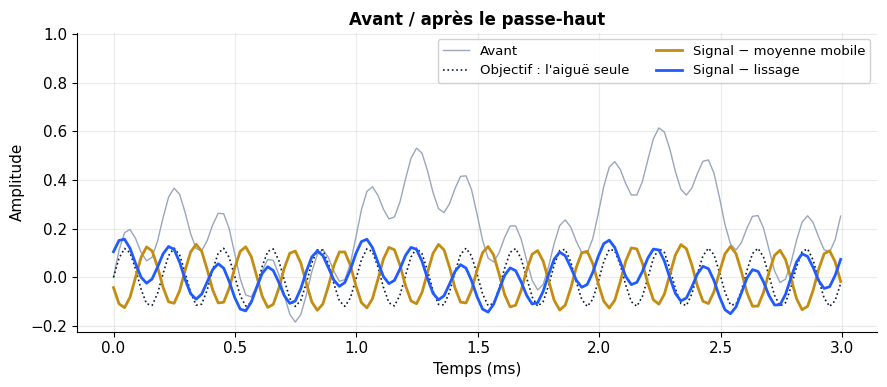

In [5]:
tracer_avant_apres(t, x, sinusoides["Aiguë 5 kHz"], "l'aiguë seule",
                   [(y_mm, OR, "Signal − moyenne mobile"), (y_exp, BLEU, "Signal − lissage")],
                   duree_ms=3, titre="Avant / après le passe-haut")

**À observer :**

les sorties oscillent vite autour de zéro, comme l'aiguë : la grande ondulation de la grave a disparu.

### Dans les fréquences

**Cellule suivante :** compare les spectres et donne la variation de chaque note en dB.

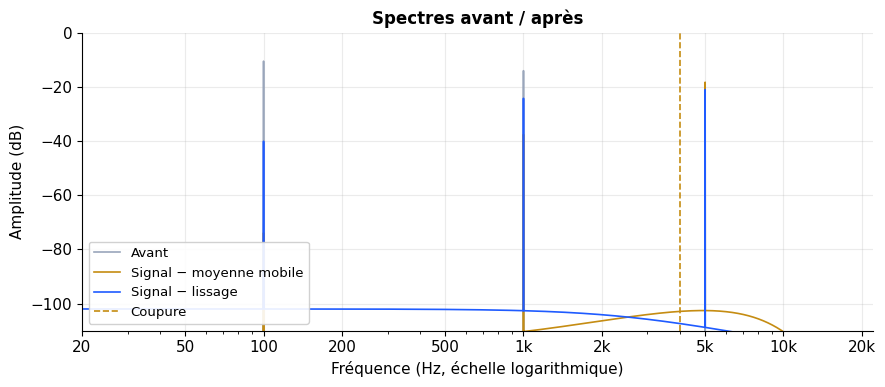

,Signal − moyenne mobile,Signal − lissage
Note,,
Grave 100 Hz,-63.4 dB,-29.6 dB
Médium 1 kHz,-23.6 dB,-10.2 dB
Aiguë 5 kHz,+0.2 dB,-2.6 dB


In [6]:
sorties = [(y_mm, OR, "Signal − moyenne mobile"), (y_exp, BLEU, "Signal − lissage")]
tracer_spectres(x, sorties, NOTES, coupures=[FC])
tableau_notes(x, sorties, NOTES)

**À observer :**

- C'est l'inverse du passe-bas : l'aiguë passe, la grave et la médium baissent fortement.
- L'aiguë perd un peu avec le lissage, car 5 kHz est encore tout près de la coupure.

### La réponse en fréquence

**Cellule suivante :** mesure la réponse des deux passe-haut, de 30 Hz à 20 kHz.

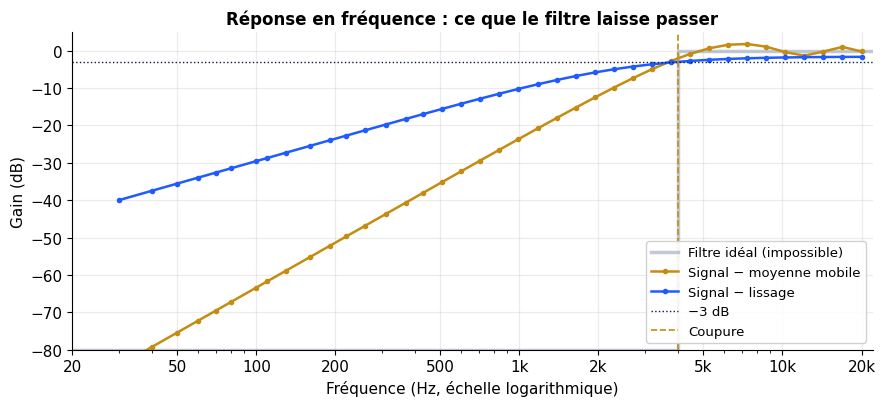

In [7]:
f_mm, g_mm = reponse_mesuree(lambda s: passe_haut_moyenne(s, M))
f_exp, g_exp = reponse_mesuree(lambda s: passe_haut_lissage(s, alpha))
tracer_reponses([(f_mm, g_mm, OR, "Signal − moyenne mobile"), (f_exp, g_exp, BLEU, "Signal − lissage")],
                coupures=[FC], ideal=([20, FC, FC, FS / 2], [-80, -80, 0, 0]))

**À observer :**

- Les courbes sont le **miroir** de celles du passe-bas : elles montent vers les aigus.
- La version « moyenne mobile » descend plus vite vers les graves. La version « lissage » descend régulièrement.

### À l'écoute

**Cellule suivante :** affiche l'original et les deux versions filtrées.

In [8]:
ecouter(x, "Avant")
ecouter(y_mm, "Signal − moyenne mobile")
ecouter(y_exp, "Signal − lissage")

Avant — crête : 0.61


Signal − moyenne mobile — crête : 0.14


Signal − lissage — crête : 0.16


**À observer :**

il ne reste qu'un **son aigu et fin** : la grave et la médium ont presque disparu.

## 7. Monter le volume des aigus

Même recette que pour les graves : `aigus = passe_haut(x)`, `reste = x − aigus`, puis `x_eq = reste + facteur × aigus`.

**Cellule suivante :** monte les aigus de 6 dB, vérifie le retour exact à 0 dB et la crête, puis affiche graphiques, tableau et écoute.

À 0 dB, on retrouve x : True
Crête : 0.61 avant, 0.73 après


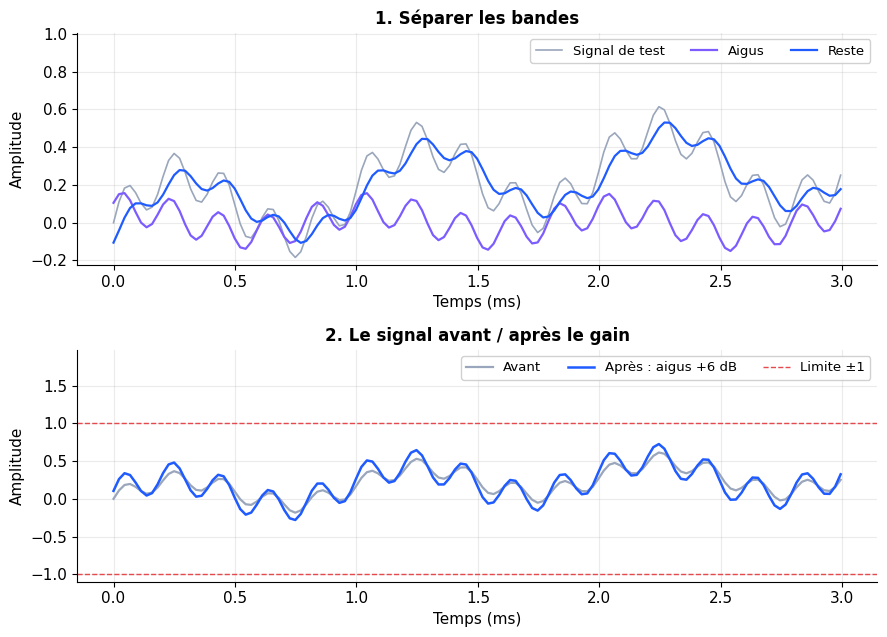

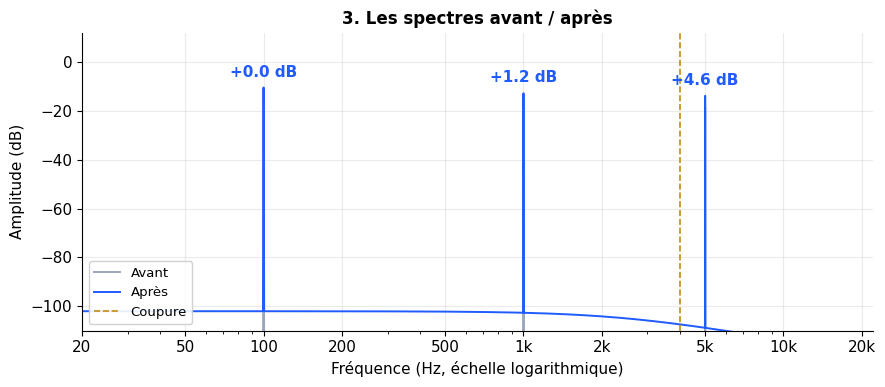

,Gain voulu,Gain obtenu
Note,,
Grave 100 Hz,+0.0 dB,+0.0 dB
Médium 1 kHz,+0.0 dB,+1.2 dB
Aiguë 5 kHz,+6.0 dB,+4.6 dB


Avant — crête : 0.61


Aigus +6 dB — crête : 0.73


In [9]:
G_DB = 6.0
facteur = 10 ** (G_DB / 20)

aigus = passe_haut_lissage(x, alpha)          # 1. isoler les aigus
reste = x - aigus                             # 2. le reste
x_eq = reste + facteur * aigus                # 3. amplifier puis recombiner

print("À 0 dB, on retrouve x :", np.allclose(reste + aigus, x))
print(f"Crête : {np.max(np.abs(x)):.2f} avant, {np.max(np.abs(x_eq)):.2f} après")

tracer_egalisation(t, x, x_eq, [(aigus, VIOLET, "Aigus"), (reste, BLEU, "Reste")],
                   NOTES, coupures=[FC], titre_apres=f"aigus {G_DB:+.0f} dB", duree_ms=3)
display(tableau_gains(x, x_eq, NOTES, {"Grave 100 Hz": 0, "Médium 1 kHz": 0, "Aiguë 5 kHz": G_DB}))
ecouter(x, "Avant")
ecouter(x_eq, f"Aigus {G_DB:+.0f} dB")

**À observer :**

- L'aiguë monte, mais moins que les 6 dB demandés : à 5 kHz, elle est encore près de la coupure, donc une partie seulement passe dans les « aigus ».
- La médium monte un peu : le filtre en laisse fuir une partie dans les aigus.

## 8. À retenir

- Un **passe-haut** garde les aigus et atténue les graves.
- On l'obtient **en retirant au signal ce que garde un passe-bas** : `passe_haut(x) = x − passe_bas(x)`.
- Avec la moyenne mobile, il faut d'abord **aligner** le signal sur le retard de la moyenne.
- Quand une formule ne donne pas le bon réglage, on peut **chercher la valeur en essayant** et en mesurant.
- EGALIZE calcule ses aigus ainsi : `aigus = x − passe_bas(x, 4 kHz)`.

**Essayez :** passez `FC` à 500 Hz. La médium (1 kHz) passe-t-elle maintenant ?